## Setup

Extraction of studies via Databases & Registers

In [3]:
# Standard Packages 
import numpy as np
import pandas as pd
import unicodedata
import time
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from datetime import datetime
from typing import Dict, List, Optional, Iterable, Tuple
from difflib import SequenceMatcher
from pathlib import Path
import unicodedata
import rispy
import bibtexparser
import itertools

# API Call Packages
import urllib
import requests
import json

# Sklearn Packages
from sklearn.metrics import cohen_kappa_score

In [ ]:
# Define path to the project folder
base = Path.cwd().parent
base

# 1. Trial API Fetch

## Load API Keys

In [ ]:
load_dotenv()

# load api keys from .env
api_key_WoS = os.getenv('WEB_OF_SCIENCE_API_KEY')
api_key_SS = os.getenv('SEMANTIC_SCHOLAR_API_KEY')

# Check if API keys are loaded
print(f"Web of Science API key loaded: {bool(api_key_WoS)}")  
print(f"Semantic Scholar API key loaded: {bool(api_key_SS)}")  

## Web of Science API Call

**Search and field tags for Web of Science documents**
- `sort_field`: Order by field(s). 
    - Field name and order by clause separated by '+', use A for ASC and D for DESC, 
    - Example: `PY+D`. Multiple values are separated by comma. 
    - Supported fields:  * **LD** - Load Date * **PY** - Publication Year * **RS** - Relevance * **TC** - Times Cited  (optional)
- `...time_span`: Beginning and end dates must be specified in the yyyy-mm-dd format separated by '+' or ' ', e.g. 2023-01-01+2023-12-31. This parameter is not compatible with the all databases search, i.e. db=WOK is not compatible with this parameter. (optional)


In [3]:
# Import WoS API client
import clarivate.wos_starter.client
from clarivate.wos_starter.client.rest import ApiException
from pprint import pprint

In [4]:
# Set up Web of Science API client
BASE_WoS = "https://api.clarivate.com/apis/wos-starter/v1"
configuration = clarivate.wos_starter.client.Configuration(host = BASE_WoS)
configuration.api_key['ClarivateApiKeyAuth'] = api_key_WoS

In [ ]:
# Define Functions 
# -------------- Function to run API query --------------
def run_wos_api(
        q,                          # Search query in WOS search syntax
        db='WOS',                       # Choice of Database
        limit=50,                       # Set limit of records on page (1-50) (default to 10)
        page=1,                         # Set the result page 
        sort_field='RS+D',              # Order by Field(s), option: LD, PY, RS, TC
        modified_time_span=None,        # Date range in which results were most recently modified.
        tc_modified_time_span=None,     # Date range in which times cited counts were modified.
        detail=None,                    # Set to returns full data by default, alternative: detail=short
        configuration=configuration ):

    with clarivate.wos_starter.client.ApiClient(configuration) as api_client:
        api_instance = clarivate.wos_starter.client.DocumentsApi(api_client)
        try:
            api_response = api_instance.documents_get(
                q,
                db=db,
                limit=limit,
                page=page,
                sort_field=sort_field,
                modified_time_span=modified_time_span,
                tc_modified_time_span=tc_modified_time_span,
                detail=detail
            )
            return api_response
        
        except ApiException as e:
            print(f"Exception when calling DocumentsApi->documents_get: {e}")
            return None
        
# -------------- Function to Fetch --------------
# Funciton: Fetch X number of pages
def wos_fetch_pages(q: str, limit: int = 50) -> pd.DataFrame:
    all_hits = []

    for p in range(1, 11):  # pages 1-10
        resp = run_wos_api(q, page=p, limit=limit)
        if resp is None:
            print(f"[WARN] No response for page {p}")
            continue
        hits = getattr(resp, "hits", []) or []
        all_hits.extend(h.to_dict() for h in hits)

    if not all_hits:
        return pd.DataFrame()

    df = pd.DataFrame(all_hits)
    if "uid" in df.columns:
        df = df.drop_duplicates(subset=["uid"]).reset_index(drop=True)
    return df

# Funciton: Fetch ALL pages
def wos_fetch_all_pages(q: str, limit: int = 50) -> pd.DataFrame:
    # Step 1: Fetch the first page to get the total number of records
    resp = run_wos_api(q, page=1, limit=limit)
    if resp is None:
        print(f"[WARN] No response for the first page of query: {q}")
        return pd.DataFrame()

    total_records = getattr(resp.metadata, "total", 0)  # Get the total number of records
    if total_records == 0:
        print(f"[WARN] No records found for query: {q}")
        return pd.DataFrame()

    # Step 2: Calculate the number of pages required
    total_pages = (total_records + limit - 1) // limit  # equivalent to math.ceil(total_records / limit)

    # Step 3: Loop through all pages and collect the records
    all_hits = []
    for page in range(1, total_pages + 1):
        resp = run_wos_api(q, page=page, limit=limit)
        if resp is None:
            print(f"[WARN] No response for page {page} of query: {q}")
            continue

        hits = getattr(resp, "hits", []) or []
        all_hits.extend(h.to_dict() for h in hits)

    if not all_hits:
        return pd.DataFrame()

    # Step 4: Convert the results to a DataFrame
    df = pd.DataFrame(all_hits)
    
    # Deduplicate based on 'uid' (unique identifier)
    if "uid" in df.columns:
        df = df.drop_duplicates(subset=["uid"]).reset_index(drop=True)

    return df

# Function: Get total record counts for each query
def wos_query_totals(wos_queries: dict) -> pd.DataFrame:
    results = []
    for name, q in wos_queries.items():
        resp = run_wos_api(q, page=1, limit=1)
        print(f"Processing query: {name}")
        
        if resp is None:
            results.append({"QueryName": name, "TotalRecords": None})
            continue

        total = getattr(resp.metadata, "total", None)
        results.append({"QueryName": name, "TotalRecords": total})

    return pd.DataFrame(results).sort_values("TotalRecords", ascending=False).reset_index(drop=True)

In [ ]:
# Define search terms

# 1. LLM Block
LLM_Block = 'TS=("large language model*" OR "foundation model*" OR LLM OR LLMs OR GPT OR LLaMA* OR Mistral OR Mixtral OR Claude* OR Gemini OR PaLM OR Qwen OR DeepSeek OR "Falcon 180B" OR "Phi-3")'

# 2. Survey Block
Survey_Block = 'TS=(survey* OR "survey data" OR "survey response*" OR questionnaire* OR question* OR "opinion poll*" OR "public opinion*" OR attitude* OR value* OR norm* OR moral* OR "feeling thermometer*" OR "open-ended" OR "open ended" OR nonresponse OR "non-response" OR respondent* OR participant* OR interview* OR "self-report*" OR "data collection")'

# 3. Simulation Block 
Simulation_BlockA = 'TS=((simulat* OR emulat* OR predict* OR imput* OR "missing data" OR nonresponse OR "non-response" OR "item nonresponse" OR "unit nonresponse" OR "synthetic respondent*" OR "synthetic participant*" OR "artificial respondent*" OR "artificial participant*" OR "virtual respondent*" OR "virtual participant*" OR persona* OR "role play*") NEAR/5 (survey* OR questionnaire* OR respondent* OR response* OR interview* OR "self-report*" OR "data collection" OR opinion* OR poll*))'

Simulation_BlockB = 'TS=( ( simulat* OR emulat* OR predict* OR imput* OR "synthetic data" OR "missing data" OR nonresponse OR "non-response" OR "item nonresponse" OR "synthetic respondent*" OR "synthetic participant*" OR "artificial respondent*" OR "artificial participant*" OR "virtual respondent*" OR "virtual participant*" OR persona* OR "role play*" OR "as a respondent" OR "LLM as respondent" OR "model as respondent" OR proxy OR surrogate OR "stand-in" OR "stand in" OR replac* OR substitut* OR represent* OR fidelit* OR faithful* OR doppelg* OR ("Synthetic Voice*" NEAR/5 (persona* OR respondent* OR survey* OR "public opinion*" OR opinion*)) OR ("representing people" NEAR/3 (survey* OR respondent* OR persona* OR opinion*)) OR ("LLM-generated persona*" OR "LLM generated persona*") ) NEAR/5 (survey* OR questionnaire* OR respondent* OR response* OR interview* OR "self-report*" OR "data collection" OR opinion* OR poll* OR attitude* OR value* OR norm* OR "public opinion*") )'

Simulation_BlockC = 'TS=("survey simulation" OR "simulated participant*" OR "simulated respondent*" OR "synthetic data" OR "synthetic survey data" OR "synthetic respondent*" OR "synthetic participant*" OR "artificial respondent*" OR "artificial participant*" OR "virtual respondent*" OR "virtual participant*" OR "LLM as respondent" OR "model as respondent" OR "as a respondent" OR "role play*" OR persona*)'

# 4. Model Training Block (optional)
Methods_Block = 'TS=( prompt* OR "few-shot" OR "few-shot learning" OR "zero-shot" OR "zero-shot learning" OR "in-context learning" OR ICL OR "chain of thought" OR "self-consistency" OR "system message" OR persona OR personas OR "role prompt*" OR "instruction-tun*" OR "instruction prompt*" OR "fine-tun*" OR ("reinforcement learning with human feedback" OR RLHF) OR ("reinforcement learning with AI feedback" OR RLAIF) OR "temperature parameter" OR "temperature setting" OR "nucleus sampling" OR "top-p sampling" OR "active learning" OR "transfer learning" OR "meta learning" OR "meta-learning" OR "representation learning" OR "continual learning" OR "lifelong learning" )'

# Year Filter Block (e.g., 2020-2024)
Year_Block = 'PY=(2022-2025)'

In [ ]:
# Create combinations of search blocks 
LLM_and_SimulationA = f'{LLM_Block} AND {Simulation_BlockA} AND {Year_Block}'
LLM_and_SimulationB = f'{LLM_Block} AND {Simulation_BlockB} AND {Year_Block}'
LLM_and_SimulationC = f'{LLM_Block} AND {Simulation_BlockC} AND {Year_Block}'
LLM_and_Survey_and_SimulationA = f'{LLM_Block} AND {Survey_Block} AND {Simulation_BlockA} AND {Year_Block}'
LLM_and_Survey_and_SimulationB = f'{LLM_Block} AND {Survey_Block} AND {Simulation_BlockB} AND {Year_Block}'
LLM_and_Survey_and_SimulationC = f'{LLM_Block} AND {Survey_Block} AND {Simulation_BlockC} AND {Year_Block}'
LLM_and_SimulationA_and_Methods = f'{LLM_Block} AND {Simulation_BlockA} AND {Methods_Block} AND {Year_Block}'
LLM_and_SimulationB_and_Methods = f'{LLM_Block} AND {Simulation_BlockB} AND {Methods_Block} AND {Year_Block}'
LLM_and_SimulationC_and_Methods = f'{LLM_Block} AND {Simulation_BlockC} AND {Methods_Block} AND {Year_Block}'

In [ ]:
# DEFINE Set of Queries
wos_queries = {
    "LLM_and_SimulationA": LLM_and_SimulationA,
    "LLM_and_SimulationB": LLM_and_SimulationB,
    "LLM_and_SimulationC": LLM_and_SimulationC,
    "LLM_and_Survey_and_SimulationA": LLM_and_Survey_and_SimulationA,
    "LLM_and_Survey_and_SimulationB": LLM_and_Survey_and_SimulationB,
    "LLM_and_Survey_and_SimulationC": LLM_and_Survey_and_SimulationC,
    "LLM_and_SimulationA_and_Methods": LLM_and_SimulationA_and_Methods,
    "LLM_and_SimulationB_and_Methods": LLM_and_SimulationB_and_Methods,
    "LLM_and_SimulationC_and_Methods": LLM_and_SimulationC_and_Methods
}

In [ ]:
# RUN: Get Max Total records
df_WoS_totals = wos_query_totals(wos_queries)
df_WoS_totals

In [ ]:
# RUN Fetch for ALL queries
dfs_WoS = {}
for name, query in wos_queries.items():
    print(f"\nFetching WoS results for: {name}")
    df = wos_fetch_all_pages(query, limit=50)
    print(f"{name}: {len(df)} rows")
    dfs_WoS[name] = df

In [32]:
# Define Functions to clean and normalize WoS DataFrames
def authors_from_names(names_obj):
    if isinstance(names_obj, dict):
        people = names_obj.get("authors") or []
        out = []
        for a in people:
            if isinstance(a, dict):
                dn = a.get("displayName") or a.get("wosStandard") or a.get("full_name") or ""
                if dn:
                    out.append(dn)
        return "; ".join(out)
    return ""

def keywords_from_obj(keywords_obj):
    if isinstance(keywords_obj, dict):
        ak = keywords_obj.get("authorKeywords")
        if isinstance(ak, list):
            return "; ".join([k for k in ak if isinstance(k, str)])
        if isinstance(ak, str):
            return ak
    return ""

def doi_from_identifiers(ident_obj):
    if isinstance(ident_obj, dict):
        doi = ident_obj.get("doi")
        if doi:
            return doi
        dois = ident_obj.get("dois")
        if isinstance(dois, list) and len(dois) > 0:
            return dois[0]
    return None

def issn_from_identifiers(ident_obj):
    if isinstance(ident_obj, dict):
        val = ident_obj.get("issn")
        issn = val[0] if isinstance(val, list) and val else val
        return issn
    return None

def isbn_from_identifiers(ident_obj):
    if isinstance(ident_obj, dict):
        val = ident_obj.get("isbn")
        isbn = val[0] if isinstance(val, list) and val else val
        return isbn
    return None

def year_from_source(src_obj):
    if isinstance(src_obj, dict):
        return src_obj.get("publishYear") or src_obj.get("publishedYear")
    return None

def first_source_type(st_list):
    if isinstance(st_list, list) and st_list:
        return st_list[0]
    return None

def clean_wos_df(df_raw: pd.DataFrame) -> pd.DataFrame:
    if df_raw is None or df_raw.empty:
        return pd.DataFrame(columns=["title", "authors", "doi", "year", "keywords", "sourceType"])

    df = df_raw.copy()

    # Compute desired fields
    df["authors"] = df["names"].apply(authors_from_names) if "names" in df.columns else ""
    df["doi"] = df["identifiers"].apply(doi_from_identifiers) if "identifiers" in df.columns else None
    df["issn"] = df["identifiers"].apply(issn_from_identifiers) if "identifiers" in df.columns else None
    df["isbn"] = df["identifiers"].apply(isbn_from_identifiers) if "identifiers" in df.columns else None
    df["year"] = df["source"].apply(year_from_source) if "source" in df.columns else None
    df["keywords"] = df["keywords"].apply(keywords_from_obj) if "keywords" in df.columns else ""
    df["sourceType"] = df["sourceTypes"].apply(first_source_type) if "sourceTypes" in df.columns else None

    # Drop intermediate/noisy columns
    to_drop = ["uid", "types", "sourceTypes", "source", "names", "links", "citations", "identifiers"]
    df = df.drop(columns=[c for c in to_drop if c in df.columns], errors="ignore")

    # Reorder columns (keep others after the key fields)
    key_cols = [c for c in ["title", "authors", "doi", "issn", "isbn",
                            "year", "keywords", "sourceType"] if c in df.columns]
    other_cols = [c for c in df.columns if c not in key_cols]
    df = df[key_cols + other_cols]

    return df

In [ ]:
# RUN Cleaning for Allsets
dfs_WoS_clean = {name: clean_wos_df(df) for name, df in dfs_WoS.items()}

df_WoS_LLM_and_SimulationA_clean = dfs_WoS_clean["LLM_and_SimulationA"]
df_WoS_LLM_and_SimulationB_clean = dfs_WoS_clean["LLM_and_SimulationB"]
df_WoS_LLM_and_SimulationC_clean = dfs_WoS_clean["LLM_and_SimulationC"]
df_WoS_LLM_and_Survey_and_SimulationA_clean = dfs_WoS_clean["LLM_and_Survey_and_SimulationA"]
df_WoS_LLM_and_Survey_and_SimulationB_clean = dfs_WoS_clean["LLM_and_Survey_and_SimulationB"]
df_WoS_LLM_and_Survey_and_SimulationC_clean = dfs_WoS_clean["LLM_and_Survey_and_SimulationC"]
df_WoS_LLM_and_SimulationA_and_Methods_clean = dfs_WoS_clean["LLM_and_SimulationA_and_Methods"]
df_WoS_LLM_and_SimulationB_and_Methods_clean = dfs_WoS_clean["LLM_and_SimulationB_and_Methods"]
df_WoS_LLM_and_SimulationC_and_Methods_clean = dfs_WoS_clean["LLM_and_SimulationC_and_Methods"]

In [ ]:
# Save cleaned dataframes to CSV files
df_WoS_LLM_and_SimulationA_clean.to_csv(base / "data/search/raw_wos/df_WoS_LLM_and_SimulationA.csv", index=False)
df_WoS_LLM_and_SimulationB_clean.to_csv(base / "data/search/raw_wos/df_WoS_LLM_and_SimulationB.csv", index=False)
df_WoS_LLM_and_SimulationC_clean.to_csv(base / "data/search/raw_wos/df_WoS_LLM_and_SimulationC.csv", index=False)
df_WoS_LLM_and_Survey_and_SimulationA_clean.to_csv(base / "data/search/raw_wos/df_WoS_LLM_and_Survey_and_SimulationA.csv", index=False)
df_WoS_LLM_and_Survey_and_SimulationB_clean.to_csv(base / "data/search/raw_wos/df_WoS_LLM_and_Survey_and_SimulationB.csv", index=False)
df_WoS_LLM_and_Survey_and_SimulationC_clean.to_csv(base / "data/search/raw_wos/df_WoS_LLM_and_Survey_and_SimulationC.csv", index=False)
df_WoS_LLM_and_SimulationA_and_Methods_clean.to_csv(base / "data/search/raw_wos/df_WoS_LLM_and_SimulationA_and_Methods.csv", index=False)
df_WoS_LLM_and_SimulationB_and_Methods_clean.to_csv(base / "data/search/raw_wos/df_WoS_LLM_and_SimulationB_and_Methods.csv", index=False)
df_WoS_LLM_and_SimulationC_and_Methods_clean.to_csv(base / "data/search/raw_wos/df_WoS_LLM_and_SimulationC_and_Methods.csv", index=False)

In [15]:
# Load up the saved cleaned dataframes
df_WoS_LLM_and_SimulationA_clean = pd.read_csv(base / "data/search/raw_wos/df_WoS_LLM_and_SimulationA.csv")
df_WoS_LLM_and_SimulationB_clean = pd.read_csv(base / "data/search/raw_wos/df_WoS_LLM_and_SimulationB.csv")
df_WoS_LLM_and_SimulationC_clean = pd.read_csv(base / "data/search/raw_wos/df_WoS_LLM_and_SimulationC.csv")
df_WoS_LLM_and_Survey_and_SimulationA_clean = pd.read_csv(base / "data/search/raw_wos/df_WoS_LLM_and_Survey_and_SimulationA.csv")
df_WoS_LLM_and_Survey_and_SimulationB_clean = pd.read_csv(base / "data/search/raw_wos/df_WoS_LLM_and_Survey_and_SimulationB.csv")
df_WoS_LLM_and_Survey_and_SimulationC_clean = pd.read_csv(base / "data/search/raw_wos/df_WoS_LLM_and_Survey_and_SimulationC.csv")
df_WoS_LLM_and_SimulationA_and_Methods_clean = pd.read_csv(base / "data/search/raw_wos/df_WoS_LLM_and_SimulationA_and_Methods.csv")
df_WoS_LLM_and_SimulationB_and_Methods_clean = pd.read_csv(base / "data/search/raw_wos/df_WoS_LLM_and_SimulationB_and_Methods.csv")
df_WoS_LLM_and_SimulationC_and_Methods_clean = pd.read_csv(base / "data/search/raw_wos/df_WoS_LLM_and_SimulationC_and_Methods.csv")

## Semantic Scholar API Call

In [2]:
from semanticscholar import SemanticScholar

In [47]:
# Define Search Parameters
FIELDS_SS = ["paperId", "title", "year", "authors", "abstract", "url", 
             "citationCount", "externalIds", "publicationTypes"]
YEAR_FILTER = "2020-"
BULK_SORT = "citationCount:desc"
MAX_PAPERS_PER_GROUP = 1000

In [87]:
# Define Search Function

# -------- Helper Functions --------
def author_names(paper_authors):
    if not paper_authors:
        return ""
    names = []
    for a in paper_authors:
        # supports Author objects and dicts
        names.append(getattr(a, "name", a.get("name") if isinstance(a, dict) else None))
    return ", ".join([n for n in names if n])

def _safe_get(container, key):
    """Access dict or object attribute safely."""
    if container is None:
        return None
    if isinstance(container, dict):
        return container.get(key)
    return getattr(container, key, None)

def _fos_to_str(x):
    if not x:
        return None
    vals = []
    if isinstance(x, list):
        for it in x:
            if isinstance(it, str):
                vals.append(it)
            elif isinstance(it, dict):
                vals.append(it.get("name") or it.get("category"))
            else:
                vals.append(getattr(it, "name", None) or getattr(it, "category", None))
    if not vals:
        return None
    vals = [v for v in vals if v]
    return "; ".join(sorted(set(vals))) if vals else None

def _enrich_fos_with_batch(df: pd.DataFrame, sch: SemanticScholar) -> pd.DataFrame:
    ids = [i for i in df.get("paperId", pd.Series()).dropna().astype(str).unique().tolist() if i]
    if not ids:
        df[["fieldsOfStudy", "s2FieldsOfStudy"]] = None
        return df
    chunksize = 100  # /graph/v1/paper/batch limit
    rows = []
    for i in range(0, len(ids), chunksize):
        batch = ids[i:i+chunksize]
        papers = sch.get_papers(batch, fields=["paperId", "fieldsOfStudy", "s2FieldsOfStudy"])
        for p in papers or []:
            pid = getattr(p, "paperId", None)
            fos = getattr(p, "fieldsOfStudy", None)
            s2  = getattr(p, "s2FieldsOfStudy", None)
            rows.append({
                "paperId": pid,
                "fieldsOfStudy": _fos_to_str(fos),
                "s2FieldsOfStudy": _fos_to_str(s2),
            })
    fos_df = pd.DataFrame(rows).drop_duplicates(subset=["paperId"]) if rows else pd.DataFrame(columns=["paperId","fieldsOfStudy","s2FieldsOfStudy"])
    return df.merge(fos_df, on="paperId", how="left")

def ss_paper_row(p):
    ext = getattr(p, "externalIds", None)

    return {
        "paperId": getattr(p, "paperId", None),
        "title": getattr(p, "title", None),
        "year": getattr(p, "year", None),
        "authors": author_names(getattr(p, "authors", None)),
        "abstract": getattr(p, "abstract", None),
        "url": getattr(p, "url", None),
        "citationCount": getattr(p, "citationCount", None),
        "doi": _safe_get(ext, "DOI") or _safe_get(ext, "doi"),
        "publicationTypes": getattr(p, "publicationTypes", None),
    }

# -------- Main Fetch Function --------

# Funciton: Fetch all pages
def ss_fetch_bulk(tag: str,
                  year_filter: str = YEAR_FILTER,
                  max_papers: int = MAX_PAPERS_PER_GROUP,
                  sort: str | None = BULK_SORT,
                  enrich_fos: bool = True) -> pd.DataFrame:
    if tag not in QUERY_GROUPS:
        raise ValueError(f"Unknown group '{tag}'. Valid keys: {', '.join(QUERY_GROUPS.keys())}")

    sch = SemanticScholar(api_key=api_key_SS, timeout=45, retry=True)
    results = sch.search_paper(
        query=QUERY_GROUPS[tag],
        year=year_filter,
        fields=FIELDS_SS,
        bulk=True,
        sort=sort,
    )

    print(f"Estimated total: {getattr(results, 'total', 'n/a')}")
    rows = []
    for i, p in enumerate(results, 1):
        rows.append(ss_paper_row(p))
        if i >= max_papers:
            break

    df = pd.DataFrame(rows)
    if enrich_fos:
        df = _enrich_fos_with_batch(df, sch)

    desired = [
        "paperId", "title", "year", "authors", "abstract", "url", "citationCount", "doi", "publicationTypes", "fieldsOfStudy", "s2FieldsOfStudy",
    ]
    for c in desired:
        if c not in df.columns:
            df[c] = None
    others = [c for c in df.columns if c not in desired]
    return df[desired + others]

# Function: Get total record counts for each query
def ss_query_totals(query_groups: dict,
                    year_filter: str = YEAR_FILTER,) -> pd.DataFrame:
    sch = SemanticScholar
    sch = SemanticScholar(api_key=api_key_SS, timeout=45, retry=True)
    results = []
    for name, query in query_groups.items():
        res = sch.search_paper(
            query=query,
            year=year_filter,
            fields=FIELDS_SS,
            bulk=True,
            sort=BULK_SORT
        )
        total = getattr(res, "total", None)
        results.append({"QueryName": name, "TotalRecords": total})    
    return pd.DataFrame(results).sort_values("TotalRecords", ascending=False).reset_index(drop=True)


In [ ]:
# Define Search Query Blocks

# 1. LLM Block
LLM_Block = ('("large language model*" | "foundation model*" | LLM | LLMs | GPT | LLaMA* | Mistral | Mixtral | Claude* | Gemini | PaLM | Qwen | DeepSeek | "Falcon 180B" | "Phi-3")')

# 2. Survey Block
Survey_Block = ('(survey* | "survey data" | "survey response*" | questionnaire* | question* | "opinion poll*" | "public opinion*" | attitude* | value* | norm* | moral* | "feeling thermometer*" | "open-ended" | "open ended" | nonresponse | "non-response" | respondent* | participant* | interview* | "self-report*" | "data collection")')

# 3. Simulation Block
Simulation_BlockA = ('((estimate* | simulat* | emulat* | predict* | imput* |  "item nonresponse" | "synthetic respondent*" | "synthetic participant*" | "artificial respondent*" |  "artificial participant*" | "virtual respondent*" | "virtual participant*" | persona* | "role play*") + (survey* | questionnaire* | respondent* | response* | interview* | "self-report*" |  "data collection" | opinion* | poll*))')

Simulation_BlockB = ('( simulat* | emulat* | predict* | imput* | "synthetic data"|  "item nonresponse" | "synthetic respondent" | "synthetic respondents" | "synthetic participant" |  "synthetic participants" | "artificial respondent" | "artificial participant" | "virtual respondent" | "virtual participant" | persona | personas |  "role play" | "role-playing" | (role + play*) |  "as a respondent" | "LLM as respondent" | "model as respondent" | proxy | surrogate | "stand-in" | "stand in" | replac* | substitut* | represent* | fidelit* | faithful* | doppelg* | ("Synthetic Voice persona"~5 | "persona Synthetic Voice"~5 |   "representing people survey"~5 | "survey representing people"~5 |  "representing people respondent"~5 | "respondent representing people"~5) )')

Simulation_BlockC = ('( "survey simulation" | "simulated participant" | "simulated respondent" |  "synthetic data" | "synthetic survey data" | "synthetic respondent" | "synthetic participant" |  "artificial respondent" | "artificial participant" | "virtual respondent" | "virtual participant" |  "LLM as respondent" | "model as respondent" | "as a respondent" | "role play" | "role-playing" | persona | personas)')

# 4. Model Training Block (optional)
Methods_Block = ('(prompt* | "few-shot" | "few-shot learning" | "zero-shot" | "zero-shot learning" | "in-context learning" | ICL | "chain of thought" | "self-consistency" | "system message" | persona | personas | "role prompt*" | "instruction-tun*" | "instruction prompt*" | "fine-tun*" | ("reinforcement learning with human feedback" | RLHF) | ("reinforcement learning with AI feedback" | RLAIF) | "temperature parameter" | "temperature setting" | "nucleus sampling" | "top-p sampling" | "active learning" | "transfer learning" | "meta learning" | "meta-learning" | "representation learning" | "continual learning" | "lifelong learning")')

# Combinations using + for AND and | for OR
QUERY_GROUPS = {
    "ss_llm_simA":             f'{LLM_Block} + {Simulation_BlockA}',
    "ss_llm_simB":             f'{LLM_Block} + {Simulation_BlockB}',
    "ss_llm_simC":             f'{LLM_Block} + {Simulation_BlockC}',
    "ss_llm_survey_simA":      f'{LLM_Block} + {Survey_Block} + {Simulation_BlockA}',
    "ss_llm_survey_simB":      f'{LLM_Block} + {Survey_Block} + {Simulation_BlockB}',
    "ss_llm_survey_simC":      f'{LLM_Block} + {Survey_Block} + {Simulation_BlockC}',
    "ss_llm_simA_methods":     f'{LLM_Block} + {Simulation_BlockA} + {Methods_Block}',
    "ss_llm_simB_methods":     f'{LLM_Block} + {Simulation_BlockB} + {Methods_Block}',
    "ss_llm_simC_methods":     f'{LLM_Block} + {Simulation_BlockC} + {Methods_Block}',

}

In [ ]:
# Run: Get Max Total records available
df_SS_totals = ss_query_totals(QUERY_GROUPS)
df_SS_totals

In [ ]:
# Run Fetch for all defined queries
df_SS_llm_simA = ss_fetch_bulk("ss_llm_simA", max_papers = 6012)
df_SS_llm_simB = ss_fetch_bulk("ss_llm_simB", max_papers = 10000)
df_SS_llm_simC = ss_fetch_bulk("ss_llm_simC", max_papers = 4574)
df_SS_llm_survey_simA = ss_fetch_bulk("ss_llm_survey_simA", max_papers = 3550)
df_SS_llm_survey_simB = ss_fetch_bulk("ss_llm_survey_simB", max_papers = 14893)
df_SS_llm_survey_simC = ss_fetch_bulk("ss_llm_survey_simC", max_papers = 1939)
df_SS_llm_simA_methods = ss_fetch_bulk("ss_llm_simA_methods", max_papers = 1839)
df_SS_llm_simB_methods = ss_fetch_bulk("ss_llm_simB_methods", max_papers = 10000)
df_SS_llm_simC_methods = ss_fetch_bulk("ss_llm_simC_methods", max_papers = 2505)


In [ ]:
# Save fetched dataframes to CSV files
df_SS_llm_simA.to_csv(base / "data/search/raw_semanticscholar/df_SS_llm_simA.csv", index=False)
df_SS_llm_simB.to_csv(base / "data/search/raw_semanticscholar/df_SS_llm_simB.csv", index=False)
df_SS_llm_simC.to_csv(base / "data/search/raw_semanticscholar/df_SS_llm_simC.csv", index=False)
df_SS_llm_survey_simA.to_csv(base / "data/search/raw_semanticscholar/df_SS_llm_survey_simA.csv", index=False)
df_SS_llm_survey_simB.to_csv(base / "data/search/raw_semanticscholar/df_SS_llm_survey_simB.csv", index=False)
df_SS_llm_survey_simC.to_csv(base / "data/search/raw_semanticscholar/df_SS_llm_survey_simC.csv", index=False)
df_SS_llm_simA_methods.to_csv(base / "data/search/raw_semanticscholar/df_SS_llm_simA_methods.csv", index=False)
df_SS_llm_simB_methods.to_csv(base / "data/search/raw_semanticscholar/df_SS_llm_simB_methods.csv", index=False)
df_SS_llm_simC_methods.to_csv(base / "data/search/raw_semanticscholar/df_SS_llm_simC_methods.csv", index=False)

In [19]:
# load saved dataframes
df_SS_llm_simA = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_llm_simA.csv")
df_SS_llm_simB = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_llm_simB.csv")
df_SS_llm_simC = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_llm_simC.csv")
df_SS_llm_survey_simA = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_llm_survey_simA.csv")
df_SS_llm_survey_simB = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_llm_survey_simB.csv")
df_SS_llm_survey_simC = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_llm_survey_simC.csv")
df_SS_llm_simA_methods = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_llm_simA_methods.csv")
df_SS_llm_simB_methods = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_llm_simB_methods.csv")
df_SS_llm_simC_methods = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_llm_simC_methods.csv")

### Filter Results



In [ ]:
EXCLUDE_FIELDS = (
    'Art|Agricultural and Food Sciences|Biology|Chemistry|Philosophy|Physics|'
    'Materials Science|Education|Engineering|Geography|Geology|History|Law|'
    'Medicine|Mechanics|Orthopedics|Pharmacology'
)
EXCLUDE_PUBTYPES = 'CaseReport|Dataset|Editorial|LettersAndComments|MetaAnalysis|News|Study'

def filter_ss_df(df):
    return df[
        df['s2FieldsOfStudy'].str.contains('Computer Science', na=False) &
        ~df['s2FieldsOfStudy'].str.contains(EXCLUDE_FIELDS, na=False) &
        ~df['publicationTypes'].str.contains(EXCLUDE_PUBTYPES, na=False)
    ]

df_SS_llm_survey_simA_filtered = filter_ss_df(df_SS_llm_survey_simA)
df_SS_llm_survey_simB_filtered = filter_ss_df(df_SS_llm_survey_simB)
df_SS_llm_survey_simC_filtered = filter_ss_df(df_SS_llm_survey_simC)

# nrows of non filtered dataframes
print(f'No. of Rows of df_SS_llm_survey_simA: {len(df_SS_llm_survey_simA)}')
print(f'No. of Rows of df_SS_llm_survey_simB: {len(df_SS_llm_survey_simB)}')
print(f'No. of Rows of df_SS_llm_survey_simC: {len(df_SS_llm_survey_simC)}')

# nrows of filtered dataframes
print(f'No. of Rows of df_SS_llm_survey_simA_filtered: {len(df_SS_llm_survey_simA_filtered)}')
print(f'No. of Rows of df_SS_llm_survey_simB_filtered: {len(df_SS_llm_survey_simB_filtered)}')
print(f'No. of Rows of df_SS_llm_survey_simC_filtered: {len(df_SS_llm_survey_simC_filtered)}')

# save filtered dataframes to CSV files
df_SS_llm_survey_simA_filtered.to_csv(base / "data/search/raw_semanticscholar/df_SS_llm_survey_simA_filtered.csv", index=False)
df_SS_llm_survey_simB_filtered.to_csv(base / "data/search/raw_semanticscholar/df_SS_llm_survey_simB_filtered.csv", index=False)
df_SS_llm_survey_simC_filtered.to_csv(base / "data/search/raw_semanticscholar/df_SS_llm_survey_simC_filtered.csv", index=False)

In [20]:
# Load up saved filtered dataframes
df_SS_llm_survey_simA_filtered = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_llm_survey_simA_filtered.csv")
df_SS_llm_survey_simB_filtered = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_llm_survey_simB_filtered.csv")
df_SS_llm_survey_simC_filtered = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_llm_survey_simC_filtered.csv")

# 2. Validate Coverage

## Load Refence Dataset

In [1]:
# Define normalization function (normalize_title)
def normalize_title(s: str) -> str:
    # Unicode normalize
    s = unicodedata.normalize("NFKC", str(s))
    # Lowercase
    s = s.lower()
    # Remove punctuation-like characters
    s = re.sub(r"[^\w\s]", " ", s)   # keep letters, numbers, underscore, whitespace
    # Collapse whitespace
    s = re.sub(r"\s+", " ", s).strip()
    return s

In [7]:
# Load the CSV of Zotero list of papers
gold_df = pd.read_csv(base / "data/search/LLM - Survey Proxies (key papers).csv")

gold_df = gold_df[["Title", "Item Type", "Abstract Note", 
                   "Publication Year", "Author", 
                   "DOI", "ISBN", "ISSN"]].drop_duplicates().reset_index(drop=True)
gold_df["preprint_flag"] = gold_df["Item Type"].apply(lambda x: "preprint" if x == "preprint" else "non-preprint")
gold_df = gold_df.rename(columns={"DOI": "doi", "ISBN": "isbn", "ISSN": "issn"})
gold_df["norm_title"] = gold_df["Title"].apply(normalize_title)

print(f"Gold list size: {len(gold_df)}")

Gold list size: 25


In [8]:
# Remove known papers that doesn't exist in WoS Dataset
bad_titles = [
    "Algorithmic Fidelity of Large Language Models in Generating Synthetic German Public Opinions: A Case Study",
    "Extracting Affect Aggregates from Longitudinal Social Media Data with Temporal Adapters for Large Language Models",
    "The Potential and Challenges of Evaluating Attitudes, Opinions, and Values in Large Language Models"
]

bad_titles_normalized = [normalize_title(t) for t in bad_titles]

gold_df = gold_df[~gold_df["norm_title"].isin(bad_titles_normalized)].reset_index(drop=True) # filter out bad titles

print(f"Cleaned Gold list size: {len(gold_df)} after removing bad entries")

Cleaned Gold list size: 22 after removing bad entries


In [9]:
# Separate sets for preprint and non-preprint for 'calc_recall_with_missing' function
gold_preprint_set = set(gold_df[gold_df["preprint_flag"] == "preprint"]["norm_title"])
gold_non_preprint_set = set(gold_df[gold_df["preprint_flag"] == "non-preprint"]["norm_title"])
gold_norm_set = set(gold_df["norm_title"])

# print the number of unique titles in each set
print(f"Unique titles in gold set: {len(gold_norm_set)}")
print(f"Unique titles in preprint set: {len(gold_preprint_set)}")
print(f"Unique titles in journals & proceedings set: {len(gold_non_preprint_set)}")

Unique titles in gold set: 22
Unique titles in preprint set: 11
Unique titles in journals & proceedings set: 11


## Define Recall Functions

In [31]:
# Define Recall Function
# ---------- Normalizers ----------
def _first_token(s: str) -> str:
    """Return the first nonempty token split on common delimiters."""
    if not isinstance(s, str): 
        return ""
    for tok in re.split(r"[;,|\s]+", s.strip()):
        if tok:
            return tok
    return ""

def normalize_doi(x: str) -> str:
    if not isinstance(x, str): 
        return ""
    x = _first_token(x).lower()
    x = re.sub(r'^(https?://(dx\.)?doi\.org/)', '', x)
    x = x.replace('\u200b', '')  # zero-width
    return x

def canonical_title(s: str) -> str:
    if not isinstance(s, str): 
        return ""
    # strip diacritics
    s = unicodedata.normalize("NFKD", s)
    s = "".join(c for c in s if not unicodedata.combining(c))
    # normalize quotes and dashes/hyphens
    s = s.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    s = s.replace("–", "-").replace("—", "-")
    s = s.lower()
    # fix known glued tokens (extend as needed)
    s = s.replace("financialwellbeing", "financial wellbeing")
    # remove punctuation except spaces and alphanumerics
    s = re.sub(r"[^a-z0-9\s]", " ", s)
    # collapse whitespace
    s = re.sub(r"\s+", " ", s).strip()
    return s

def _ensure_series(df, col):
    vals = df[col] if (isinstance(col, str) and col in df.columns) else pd.Series([""] * len(df), index=df.index)
    return vals.fillna("").astype(str)


# ---------- Main ----------
def calc_recall_with_missing(res_df,
                             gold_df = gold_df,
                             gold_cols=dict(doi="doi", title="Title"),
                             res_cols=dict(doi="doi", title="title")):
    g = gold_df.copy()
    r = res_df.copy()

    # Normalized keys (robust to missing columns)
    g["_doi"]  = _ensure_series(g, gold_cols.get("doi")).map(normalize_doi)
    r["_doi"]  = _ensure_series(r, res_cols.get("doi")).map(normalize_doi)

    g["_tkey"] = _ensure_series(g, gold_cols.get("title")).map(canonical_title)
    r["_tkey"] = _ensure_series(r, res_cols.get("title")).map(canonical_title)

    out = g[[gold_cols["title"]]].rename(columns={gold_cols["title"]: "gold_title"}).copy()
    out[["_doi", "_tkey"]] = g[["_doi", "_tkey"]]
    out["preprint_flag"] = g["preprint_flag"] if "preprint_flag" in g.columns else pd.NA
    out["matched_by"] = pd.NA
    out["matched_title"] = pd.NA

    def do_join(key: str, label: str):
        nonlocal out, r
        pending = out[out["matched_by"].isna()]
        pending = pending[pending[key].astype(bool)]
        if pending.empty or key not in r.columns:
            return
        pending = pending.assign(_row_id=pending.index)
        if res_cols.get("title") not in r.columns:
            return
        right = r[[res_cols["title"], key]].drop_duplicates(subset=key).set_index(key)
        merged = pending.join(right, on=key, how="left")
        hits = merged[merged[res_cols["title"]].notna()]
        if hits.empty:
            return
        out.loc[hits["_row_id"], "matched_by"] = label
        out.loc[hits["_row_id"], "matched_title"] = hits[res_cols["title"]].values

    # Priority order: DOI, then exact normalized title.
    # ISSN/ISBN are not used: they identify a journal or book, not an individual paper.
    do_join("_doi",  "doi")
    do_join("_tkey", "title_exact")

    matched_mask = out["matched_title"].notna()
    tp = matched_mask.sum()
    fn = (~matched_mask).sum()
    recall = tp / (tp + fn) if (tp + fn) else 0.0

    pre_mask = out["preprint_flag"].astype(str).str.lower().eq("preprint")
    non_pre_mask = out["preprint_flag"].astype(str).str.lower().eq("non-preprint")

    recall_preprint = (matched_mask & pre_mask).sum() / pre_mask.sum() if pre_mask.sum() else 0.0
    recall_non_preprint = (matched_mask & non_pre_mask).sum() / non_pre_mask.sum() if non_pre_mask.sum() else 0.0

    missing_non_pre_titles = out.loc[(~matched_mask) & non_pre_mask, "gold_title"].tolist()
    missing_pre_titles = out.loc[(~matched_mask) & pre_mask, "gold_title"].tolist()

    return pd.DataFrame([{
        "Number of Papers Retrieved": len(res_df),
        "Recall (All)": f"{recall:.2%}",
        "Recall (Journal & Conf. Papers)": f"{recall_non_preprint:.2%}",
        "Recall (Preprints)": f"{recall_preprint:.2%}",
        "Missing Journal & Conf. Papers": "; ".join(sorted(missing_non_pre_titles)),
        "Missing Preprints": "; ".join(sorted(missing_pre_titles)),
    }])

## Recall Rate - WoS

In [32]:
# Run recall calculations for Subset WoS set
wos_recall_results = {
    "LLM and SimulationA": calc_recall_with_missing(df_WoS_LLM_and_SimulationA_clean),
    "LLM and SimulationB": calc_recall_with_missing(df_WoS_LLM_and_SimulationB_clean),
    "LLM and SimulationC": calc_recall_with_missing(df_WoS_LLM_and_SimulationC_clean),
    "LLM and Survey and SimulationA": calc_recall_with_missing(df_WoS_LLM_and_Survey_and_SimulationA_clean),
    "LLM and Survey and SimulationB": calc_recall_with_missing(df_WoS_LLM_and_Survey_and_SimulationB_clean),
    "LLM and Survey and SimulationC": calc_recall_with_missing(df_WoS_LLM_and_Survey_and_SimulationC_clean),
    "LLM and SimulationA and Methods": calc_recall_with_missing(df_WoS_LLM_and_SimulationA_and_Methods_clean),
    "LLM and SimulationB and Methods": calc_recall_with_missing(df_WoS_LLM_and_SimulationB_and_Methods_clean),
    "LLM and SimulationC and Methods": calc_recall_with_missing(df_WoS_LLM_and_SimulationC_and_Methods_clean),
}

recall_table_WoS = pd.concat(wos_recall_results.values(), 
                                   keys=wos_recall_results.keys()).reset_index(level=1, drop=True).reset_index().rename(columns={"index": "Query"})

print(f"Number of records in Preprint Papers gold set: {len(gold_preprint_set)}")
print(f"Number of records in Journals & Conference Articles gold set: {len(gold_non_preprint_set)}")
recall_table_WoS

Number of records in Preprint Papers gold set: 11
Number of records in Journals & Conference Articles gold set: 11


,Query,Number of Papers Retrieved,Recall (All),Recall (Journal & Conf. Papers),Recall (Preprints),Missing Journal & Conf. Papers,Missing Preprints
0,LLM and SimulationA,561,40.91%,81.82%,0.00%,Knowledge of cultural moral norms in large lan...,AI-Augmented Surveys: Leveraging Large Languag...
1,LLM and SimulationB,1223,50.00%,100.00%,0.00%,,AI-Augmented Surveys: Leveraging Large Languag...
2,LLM and SimulationC,3827,22.73%,45.45%,0.00%,Knowledge of cultural moral norms in large lan...,AI-Augmented Surveys: Leveraging Large Languag...
3,LLM and Survey and SimulationA,320,40.91%,81.82%,0.00%,Knowledge of cultural moral norms in large lan...,AI-Augmented Surveys: Leveraging Large Languag...
4,LLM and Survey and SimulationB,922,50.00%,100.00%,0.00%,,AI-Augmented Surveys: Leveraging Large Languag...
5,LLM and Survey and SimulationC,1503,22.73%,45.45%,0.00%,Knowledge of cultural moral norms in large lan...,AI-Augmented Surveys: Leveraging Large Languag...
6,LLM and SimulationA and Methods,169,22.73%,45.45%,0.00%,Can large language models estimate public opin...,AI-Augmented Surveys: Leveraging Large Languag...
7,LLM and SimulationB and Methods,329,31.82%,63.64%,0.00%,Can large language models estimate public opin...,AI-Augmented Surveys: Leveraging Large Languag...
8,LLM and SimulationC and Methods,1406,13.64%,27.27%,0.00%,Can large language models estimate public opin...,AI-Augmented Surveys: Leveraging Large Languag...


## Recall Rate - S.S.

In [33]:
# Run recall calculations
ss_recall_results = {
    "LLM and SimulationA": calc_recall_with_missing(df_SS_llm_simA),
    "LLM and SimulationB": calc_recall_with_missing(df_SS_llm_simB),
    "LLM and SimulationC": calc_recall_with_missing(df_SS_llm_simC),
    "LLM and Survey and SimulationA": calc_recall_with_missing(df_SS_llm_survey_simA),
    "LLM and Survey and SimulationB": calc_recall_with_missing(df_SS_llm_survey_simB),
    "LLM and Survey and SimulationC": calc_recall_with_missing(df_SS_llm_survey_simC),
    "LLM and SimulationA and Methods": calc_recall_with_missing(df_SS_llm_simA_methods),
    "LLM and SimulationB and Methods": calc_recall_with_missing(df_SS_llm_simB_methods),
    "LLM and SimulationC and Methods": calc_recall_with_missing(df_SS_llm_simC_methods),
}

recall_table_SS = pd.concat(ss_recall_results.values(), 
                             keys=ss_recall_results.keys()).reset_index(level=1, drop=True).reset_index().rename(columns={"index": "Query"})
recall_table_SS


,Query,Number of Papers Retrieved,Recall (All),Recall (Journal & Conf. Papers),Recall (Preprints),Missing Journal & Conf. Papers,Missing Preprints
0,LLM and SimulationA,6012,81.82%,100.00%,63.64%,,Addressing Systematic Non-response Bias with S...
1,LLM and SimulationB,10000,40.91%,54.55%,27.27%,LLM-Based Doppelgänger Models: Leveraging Synt...,Addressing Systematic Non-response Bias with S...
2,LLM and SimulationC,4574,45.45%,63.64%,27.27%,Knowledge of cultural moral norms in large lan...,AI-Augmented Surveys: Leveraging Large Languag...
3,LLM and Survey and SimulationA,3824,81.82%,100.00%,63.64%,,Addressing Systematic Non-response Bias with S...
4,LLM and Survey and SimulationB,14893,86.36%,100.00%,72.73%,,Addressing Systematic Non-response Bias with S...
5,LLM and Survey and SimulationC,1939,45.45%,63.64%,27.27%,Knowledge of cultural moral norms in large lan...,AI-Augmented Surveys: Leveraging Large Languag...
6,LLM and SimulationA and Methods,1839,45.45%,54.55%,36.36%,Can large language models estimate public opin...,Addressing Systematic Non-response Bias with S...
7,LLM and SimulationB and Methods,10000,45.45%,54.55%,36.36%,Can large language models estimate public opin...,Addressing Systematic Non-response Bias with S...
8,LLM and SimulationC and Methods,2505,31.82%,45.45%,18.18%,Can large language models estimate public opin...,AI-Augmented Surveys: Leveraging Large Languag...


## Recall Rate

In [35]:
# Complete Recall Table
recall_table = pd.concat([
    recall_table_SS.assign(Source="Semantic Scholar"),
    recall_table_WoS.assign(Source="Web of Science")
], ignore_index=True)

recall_table.to_csv(base / "data/search/recall_table_final.csv", index=False)
recall_table

,Query,Number of Papers Retrieved,Recall (All),Recall (Journal & Conf. Papers),Recall (Preprints),Missing Journal & Conf. Papers,Missing Preprints,Source
0,LLM and SimulationA,6012,81.82%,100.00%,63.64%,,Addressing Systematic Non-response Bias with S...,Semantic Scholar
1,LLM and SimulationB,10000,40.91%,54.55%,27.27%,LLM-Based Doppelgänger Models: Leveraging Synt...,Addressing Systematic Non-response Bias with S...,Semantic Scholar
2,LLM and SimulationC,4574,45.45%,63.64%,27.27%,Knowledge of cultural moral norms in large lan...,AI-Augmented Surveys: Leveraging Large Languag...,Semantic Scholar
3,LLM and Survey and SimulationA,3824,81.82%,100.00%,63.64%,,Addressing Systematic Non-response Bias with S...,Semantic Scholar
4,LLM and Survey and SimulationB,14893,86.36%,100.00%,72.73%,,Addressing Systematic Non-response Bias with S...,Semantic Scholar
5,LLM and Survey and SimulationC,1939,45.45%,63.64%,27.27%,Knowledge of cultural moral norms in large lan...,AI-Augmented Surveys: Leveraging Large Languag...,Semantic Scholar
6,LLM and SimulationA and Methods,1839,45.45%,54.55%,36.36%,Can large language models estimate public opin...,Addressing Systematic Non-response Bias with S...,Semantic Scholar
7,LLM and SimulationB and Methods,10000,45.45%,54.55%,36.36%,Can large language models estimate public opin...,Addressing Systematic Non-response Bias with S...,Semantic Scholar
8,LLM and SimulationC and Methods,2505,31.82%,45.45%,18.18%,Can large language models estimate public opin...,AI-Augmented Surveys: Leveraging Large Languag...,Semantic Scholar
9,LLM and SimulationA,561,40.91%,81.82%,0.00%,Knowledge of cultural moral norms in large lan...,AI-Augmented Surveys: Leveraging Large Languag...,Web of Science


# 3. Full API Fetch

## Semantic Scholar

In [ ]:
# Fetch the FULL final SS dataframe
df_SS_final_FULL_raw = ss_fetch_bulk("ss_llm_survey_simA", year_filter="2000-", max_papers = 7194)
df_SS_final_FULL_raw.to_csv(base / "data/search/raw_semanticscholar/df_SS_final_FULL.csv", index=False)

df_SS_final_FULL_raw = pd.read_csv(base / "data/search/raw_semanticscholar/df_SS_final_FULL.csv")
print(f"Number of records in FULL final SS dataframe: {len(df_SS_final_FULL_raw)}")

Number of records in FULL final SS dataframe: 7194


## Web of Science

In [ ]:
# Fetch the FULL final WoS dataframe
df_WoS_final_FULL_raw = pd.read_excel(base / "data/search/raw_wos/df_WoS_LLM_and_Survey_and_SimulationA_FULL.xls")
print(f"Number of records in df_WoS_final_FULL: {len(df_WoS_final_FULL_raw)}")

Number of records in df_WoS_final_FULL: 517


# 4. Screening

## Clean Database 

In [ ]:
#print out the columns names of df_WoS_final_FULL sorted
print("Columns in df_WoS_final_FULL_raw:")
for col in sorted(df_WoS_final_FULL_raw.columns):
    print(f" - {col}")

In [13]:
# Clean and prepare Final dataframe

# WOS
df_WoS_final_FULL = df_WoS_final_FULL_raw.rename(columns={"Article Title": "title", 
                                                          'Publication Year': 'year',
                                                          'Abstract': 'abstract',
                                                          'Document Type': 'publicationTypes',
                                                          'DOI': 'doi',
                                                          "Research Areas": "researchAreas",
                                                          "Author Full Names": "authors",
                                                          'UT (Unique WOS ID)': 'paperId'})
df_WoS_final_FULL['norm_title'] = df_WoS_final_FULL['title'].map(normalize_title)
df_WoS_final_FULL = df_WoS_final_FULL[['paperId', 'title', 'year', 'authors', 'abstract', 'doi', 'publicationTypes', 'researchAreas', 'norm_title']]

# SS
df_SS_final_FULL = df_SS_final_FULL_raw.rename(columns={"s2FieldsOfStudy": "researchAreas"})
df_SS_final_FULL['publicationTypes'] = df_SS_final_FULL['publicationTypes'].apply(lambda x: ', '.join(x) if isinstance(x, list) else str(x))
df_SS_final_FULL['norm_title'] = df_SS_final_FULL['title'].map(normalize_title)
df_SS_final_FULL = df_SS_final_FULL[['paperId', 'title', 'year', 'authors', 'abstract', 'doi', 'publicationTypes', 'researchAreas', 'norm_title']]


print(f'Columns in WoS: {df_WoS_final_FULL.columns.tolist()}')
print(f'Number of records in df_WoS_final_FULL: {len(df_WoS_final_FULL)}')
print(f'Columns in SS: {df_SS_final_FULL.columns.tolist()}')
print(f'Number of records in df_SS_final_FULL: {len(df_SS_final_FULL)}')

Columns in WoS: ['paperId', 'title', 'year', 'authors', 'abstract', 'doi', 'publicationTypes', 'researchAreas', 'norm_title']
Number of records in df_WoS_final_FULL: 517
Columns in SS: ['paperId', 'title', 'year', 'authors', 'abstract', 'doi', 'publicationTypes', 'researchAreas', 'norm_title']
Number of records in df_SS_final_FULL: 7194


In [20]:
# calculate recall of df_WoS_final_FULL and df_SS_final_FULL
final_recall_results = {
    "Web of Science Final": calc_recall_with_missing(df_WoS_final_FULL),
    "Semantic Scholar Final": calc_recall_with_missing(df_SS_final_FULL),
}
pd.concat(final_recall_results.values(), 
                               keys=final_recall_results.keys()).reset_index(level=1, drop=True).reset_index().rename(columns={"index": "Query"})


,Query,Number of Papers Retrieved,Recall (All),Recall (Journal & Conf. Papers),Recall (Preprints),Missing Journal & Conf. Papers,Missing Preprints
0,Web of Science Final,517,40.00%,64.29%,9.09%,Algorithmic Fidelity of Large Language Models ...,AI-Augmented Surveys: Leveraging Large Languag...
1,Semantic Scholar Final,7194,80.00%,92.86%,63.64%,The Potential and Challenges of Evaluating Att...,Addressing Systematic Non-response Bias with S...


In [ ]:
# compare the doi of df_WoS_final and df_WoS_final_FULL, do they match?
wos_doi_set = set(df_WoS_LLM_and_Survey_and_SimulationA_clean['doi'].dropna().unique())
wos_full_doi_set = set(df_WoS_final_FULL['doi'].dropna().unique())
print(f'Number of unique DOIs in WoS: {len(wos_doi_set)}')
print(f'Number of unique DOIs in WoS FULL: {len(wos_full_doi_set)}')
print(f'Number of common DOIs in both WoS and WoS FULL: {len(wos_doi_set.intersection(wos_full_doi_set))}')

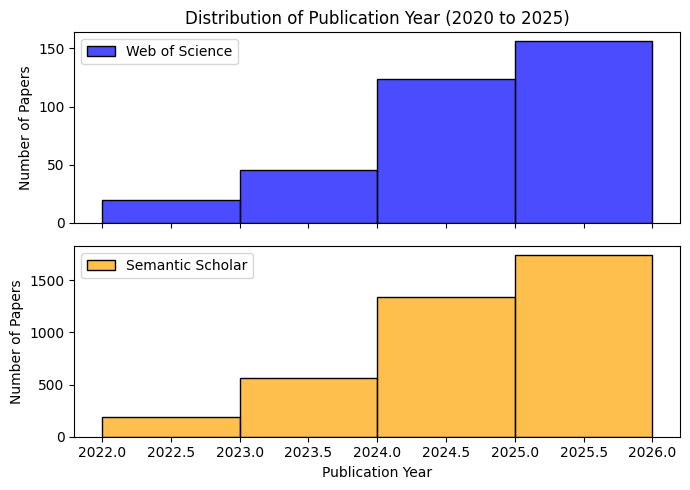

In [29]:
# Plot Distribution of Publication Years
fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True)

sns.histplot(df_WoS_final_FULL['year'], color='blue', ax=axes[0], 
             kde=False, stat='count', bins=range(2022, 2027), alpha=0.7)
axes[0].set_title('Distribution of Publication Year (2020 to 2025)')
axes[0].set_ylabel('Number of Papers')
axes[0].legend(['Web of Science'])

sns.histplot(df_SS_final_FULL['year'], color='orange', ax=axes[1], 
             kde=False, stat='count', bins=range(2022, 2027), alpha=0.7)
axes[1].set_title('')
axes[1].set_xlabel('Publication Year')
axes[1].set_ylabel('Number of Papers')
axes[1].legend(['Semantic Scholar'])

plt.tight_layout()
plt.show()

## Merge Database

In [21]:
print(f'Number of rows in df_WoS_final_FULL: {len(df_WoS_final_FULL)}')
print(f'Number of rows in df_SS_final_FULL: {len(df_SS_final_FULL)}\n')

# combine df_WoS_final_FULL, df_SS_final_FULL; and create a column 'source' to indicate the source of each row
df_combined = pd.concat([df_WoS_final_FULL.assign(source='Web of Science'),
                         df_SS_final_FULL.assign(source='Semantic Scholar')], 
                         ignore_index=True)

print(f'Number of rows in combined dataframe before dropping duplicates: {len(df_combined)}')

df_combined = df_combined.drop_duplicates(subset = ['doi']).reset_index(drop = True)
print(f'Number of rows in combined dataframe after dropping DOI duplicates: {len(df_combined)}')

df_combined = df_combined.drop_duplicates(subset=['norm_title']).reset_index(drop=True)
df_combined = df_combined.drop(columns=['norm_title'])
print(f'Number of rows in combined dataframe after dropping duplicates: {len(df_combined)}')

print(f'Number of titles dropped due to duplicate titles: {len(df_combined) - len(df_WoS_final_FULL) - len(df_SS_final_FULL)}')

calc_recall_with_missing(df_combined)

Number of rows in df_WoS_final_FULL: 517
Number of rows in df_SS_final_FULL: 7194

Number of rows in combined dataframe before dropping duplicates: 7711
Number of rows in combined dataframe after dropping DOI duplicates: 5521
Number of rows in combined dataframe after dropping duplicates: 5478
Number of titles dropped due to duplicate titles: -2233


,Number of Papers Retrieved,Recall (All),Recall (Journal & Conf. Papers),Recall (Preprints),Missing Journal & Conf. Papers,Missing Preprints
0,5478,76.00%,92.86%,54.55%,The Potential and Challenges of Evaluating Att...,Addressing Systematic Non-response Bias with S...


## Screening 1.0: Search Frame

In [26]:
# RUN Inclusion & Exclusion Criteria Final Screening

INCLUDE_FIELDS = (
    'Arts & Humanities - Other Topics|'
    'Social Sciences - Other Topics|'
    'Business & Economics|'
    'Computer Science|'
    'Information Science & Library Science|'
    'Linguistics|'
    'Political Science|'
    'Environmental Sciences & Ecology|'
    'Mathematical Methods In Social Sciences|Government & Law'
)

INCLUDE_PUBTYPES = 'Article|Proceedings Paper|Conference|JournalArticle'

EXCLUDE_FIELDS = ('Acoustics|Agricultur|Allergy|Anatomy & Morphology|Astronomy & Astrophysics|Atmospheric Sciences|Audiology & Speech-Language Pathology|Automation|Biodiversity & Conservation|Biology|Biotechnology & Applied Microbiology|Chemistry|Construction & Building Technology|Dermatology|Education|Energy & Fuels|Family Studies|Food Science & Technology|Gastroenterology & Hepatology|Geochemistry & Geophysics|Geography|Geology|Health|History|Imaging Science & Photographic Technology|Life Sciences & Biomedicine - Other Topics|Literature|Management Science|Materials Science|Mechanics|Medical|Medicine|Music|Neurosciences|Nursing|Oncology|Orthopedics|Otorhinolaryngology|Plant Sciences|Pediatrics|Pharmacology|Philosophy|Physics|Polymer Science|Psychiatry|Public Administration|Remote Sensing|Rheumatology|Robotics|Services|Social Work|Surgery|Thermodynamics|Transportation|Urology & Nephrology')

EXCLUDE_PUBTYPES = 'CaseReport|Dataset|Editorial|LettersAndComments|MetaAnalysis|News|Study'

In [ ]:
def final_screen(df):
    # Step 1: Year filter
    step1 = df[df['year'].astype(str).str.isdigit() & (df['year'].astype(int) >= 2022)]
    print(f"Rows after year filter: {len(step1)}")
    
    # Step 2: Include fields
    step2 = step1[step1['researchAreas'].str.contains(INCLUDE_FIELDS, na=False)]
    print(f"Rows after INCLUDE_FIELDS filter: {len(step2)}")
    
    # Step 3: Exclude fields
    step3 = step2[~step2['researchAreas'].str.contains(EXCLUDE_FIELDS, na=False)]
    print(f"Rows after EXCLUDE_FIELDS filter: {len(step3)}")
    
    # Step 4: Exclude publication types
    step4 = step3[~step3['publicationTypes'].str.contains(EXCLUDE_PUBTYPES, na=False)]
    print(f"Rows after EXCLUDE_PUBTYPES filter: {len(step4)}")
    
    return step4

df_final_prescreen = final_screen(df_combined)

# print number of rows before final screening
print(f'Number of rows in combined dataframe before final screening: {len(df_combined)}')
print(f'Number of rows in combined dataframe after final screening: {len(df_final_prescreen)}')

Rows after year filter: 3662
Rows after INCLUDE_FIELDS filter: 2876
Rows after EXCLUDE_FIELDS filter: 1687
Rows after EXCLUDE_PUBTYPES filter: 1683
Number of rows in combined dataframe before final screening: 5478
Number of rows in combined dataframe after final screening: 1683


In [ ]:
# Fill in the missing DOIs
df_final_prescreen.loc[df_final_prescreen['title'] == "From Values to Opinions: Predicting Human Behaviors and Stances Using Value-Injected Large Language Models", 'doi'] = "10.18653/v1/2023.emnlp-main.961"

# View missing abstracts and DOIs by source
missing_by_source = df_final_prescreen.groupby('source').agg(
    num_missing_abstract = ('abstract', lambda x: x.isna().sum()),
    num_missing_doi = ('doi', lambda x: x.isna().sum())
).reset_index()
print(missing_by_source)

             source  num_missing_abstract  num_missing_doi
0  Semantic Scholar                    54                0
1    Web of Science                     0                0


## Screening 2.0: Abstract

Export for ASreview - Save identified collection of records for screening in ASReview

In [ ]:
# Save df_final_prescreen to CSV
df_final_prescreen.to_csv(base / "data/screening/df_final_prescreen.csv", index=False)

# load df_final_prescreen
df_final_prescreen = pd.read_csv(base / "data/screening/df_final_prescreen.csv")
print(f'Number of records ident: {len(df_final_prescreen)}')


Number of rows in final combined filtered dataframe: 1683


In [ ]:
# Create a 3% sample of df_final_prescreen for test run
df_final_prescreen_sample = df_final_prescreen.sample(frac=0.03, 
                                                      random_state=42).reset_index(drop=True)
print(f'Number of rows in final prescreen 3% sample dataframe: {len(df_final_prescreen_sample)}')

# save df_final_prescreen_sample to CSV
df_final_prescreen_sample.to_csv(base / "data/screening/df_final_prescreen_sample.csv", index=False)

Number of rows in final prescreen 3% sample dataframe: 50
